In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
data = pd.DataFrame({
    "Study_Hours": [2, 4, 5, 7, 8, 10],
    "Attendance_Percent": [50, 60, 65, 75, 85, 95],
    "Assignment_Score": [35, 45, 55, 65, 80, 95],
    "Final_Marks": [38, 48, 56, 68, 82, 94]
})

display(data)

,Study_Hours,Attendance_Percent,Assignment_Score,Final_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [9]:
features = data[["Study_Hours", "Attendance_Percent", "Assignment_Score"]]

print("Minimum values:")
print(features.min())

print("\nMaximum values:")
print(features.max())

Minimum values:
Study_Hours            2
Attendance_Percent    50
Assignment_Score      35
dtype: int64

Maximum values:
Study_Hours           10
Attendance_Percent    95
Assignment_Score      95
dtype: int64


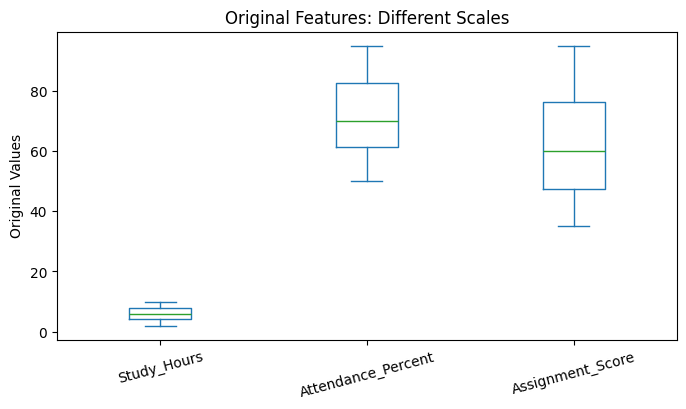

In [10]:
features.plot(kind="box", figsize=(8,4))
plt.title("Original Features: Different Scales")
plt.ylabel("Original Values")
plt.xticks(rotation=15)
plt.show()

In [11]:
normalizer = MinMaxScaler()
normalized_array = normalizer.fit_transform(features)

normalized_df = pd.DataFrame(
    normalized_array,
    columns=features.columns,
    index=features.index
)

display(normalized_df.round(3))

,Study_Hours,Attendance_Percent,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [12]:
print("Minimum after normalization:")
print(normalized_df.min())
print("\nMaximum after normalization:")
print(normalized_df.max())

Minimum after normalization:
Study_Hours           0.0
Attendance_Percent    0.0
Assignment_Score      0.0
dtype: float64

Maximum after normalization:
Study_Hours           1.0
Attendance_Percent    1.0
Assignment_Score      1.0
dtype: float64


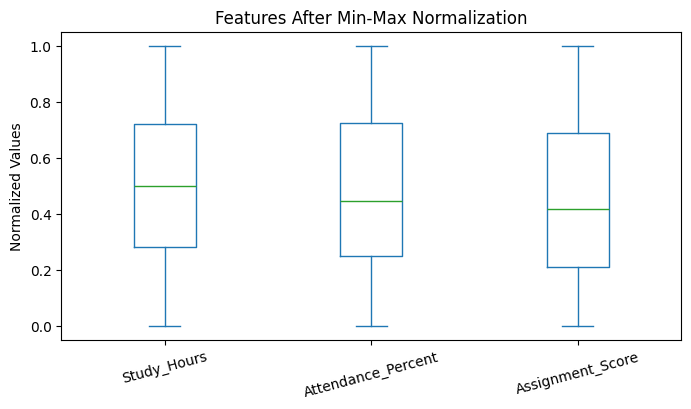

In [13]:
normalized_df.plot(kind="box", figsize=(8,4))
plt.title("Features After Min-Max Normalization")
plt.ylabel("Normalized Values")
plt.xticks(rotation=15)
plt.show()

In [14]:
standardizer = StandardScaler()
standardized_array = standardizer.fit_transform(features)

standardized_df = pd.DataFrame(
    standardized_array,
    columns=features.columns,
    index=features.index
)

display(standardized_df.round(3))

,Study_Hours,Attendance_Percent,Assignment_Score
0,-1.512,-1.427,-1.351
1,-0.756,-0.768,-0.859
2,-0.378,-0.439,-0.368
3,0.378,0.220,0.123
4,0.756,0.878,0.859
5,1.512,1.537,1.596


In [17]:
print("Means after standardization:")
print(standardized_df.mean().round(6))

print("\nStandard deviations after standardization:")
print(standardized_df.std(ddof=0).round(6))

Means after standardization:
Study_Hours           0.0
Attendance_Percent   -0.0
Assignment_Score      0.0
dtype: float64

Standard deviations after standardization:
Study_Hours           1.0
Attendance_Percent    1.0
Assignment_Score      1.0
dtype: float64


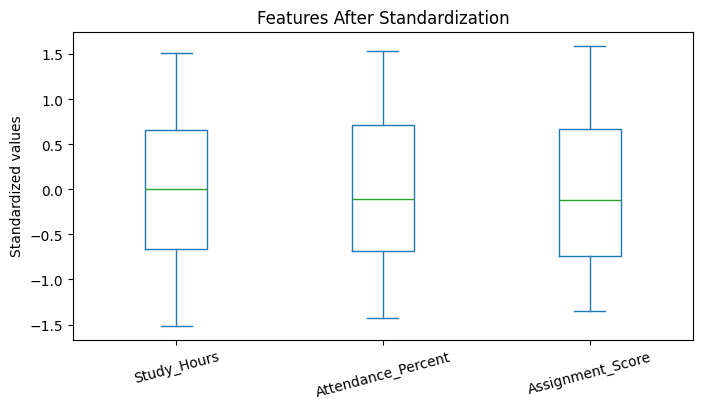

In [19]:
standardized_df.plot(kind="box", figsize=(8,4))
plt.title("Features After Standardization")
plt.ylabel("Standardized values")
plt.xticks(rotation=15)
plt.show()

In [21]:
#Step 1: Standardize the input features
scaled_features = StandardScaler().fit_transform(features)

#Step 2: Reduce 3 features to 2 principal components
pca = PCA(n_components=2)

#Step 3: Transform the scaled data
pca_array = pca.fit_transform(scaled_features)

pca_df = pd.DataFrame(
    pca_array,
    columns=["PC1", "PC2"],
    index=features.index
)

display(pca_df.round(3))

,PC1,PC2
0,-2.476,-0.115
1,-1.376,0.069
2,-0.684,-0.001
3,0.416,0.182
4,1.440,-0.078
5,2.682,-0.057


In [22]:
variance_ratios = pca.explained_variance_ratio_

for component, ratio in zip(["PC1", "PC2"], variance_ratios):
  print(f"{component} explains {ratio:.2%} of the variance")

total_retained = variance_ratios.sum()
print(f"\nTotal variance retained by 2 components: {total_retained:.2%}")

PC1 explains 99.62% of the variance
PC2 explains 0.34% of the variance

Total variance retained by 2 components: 99.96%


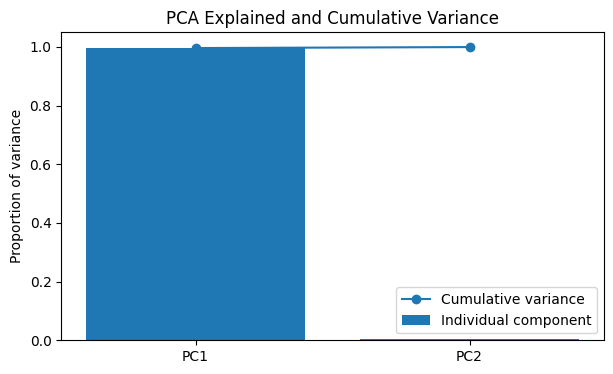

In [24]:
component_names = ["PC1", "PC2"]
cumulative_variance = variance_ratios.cumsum()

plt.figure(figsize=(7, 4))
plt.bar(component_names, variance_ratios)
plt.plot(component_names, cumulative_variance, marker="o")
plt.ylim(0, 1.05)
plt.ylabel("Proportion of variance")
plt.title("PCA Explained and Cumulative Variance")
plt.legend(["Cumulative variance", "Individual component"])
plt.show()

In [25]:
print("Number of original input features:", features.shape[1])
print("Number of PCA components:", pca_df.shape[1])
print("Original feature shape:", features.shape)
print("Reduced PCA data shape:", pca_df.shape)

Number of original input features: 3
Number of PCA components: 2
Original feature shape: (6, 3)
Reduced PCA data shape: (6, 2)
